# Part VII — The reset: past results or this weekend's pace?
**Proposal question:** *can a pre-race model predict which drivers score points (top 10) through a regulation reset, and should it rely on past results or on the current weekend's pace?*

- **H1** after a reset, weekend pace (practice, qualifying, grid) predicts better than past results
- **H2** past results regain their value as the new season progresses
- **H3** live forecasts for the remaining 2026 races are as accurate as the simulation (tested after the races)

The same logistic regression is trained with different sets of variables. Each 2014 and 2026 race is predicted by a model re-trained on everything before it (PCA and k-means included). **New variables for the reset (the 2026 power units are about 50% electric):** `pu_form` (points per car of every car with the same engine, last 5 races), `pu_works` (works or lead-partner team), `pu_change` (the team changed engine supplier this season), `prev_season_fade` (did the team fade at the end of last season? a proxy for moving resources early to the new rules; no public source gives teams' spending).
Code: `f1duel/reset.py`.

Points that changed hands over the winter: 2014 42%, 2026 34% (median of other years 21%)
Mechanical retirements: 2025 3% -> 2026 13%; 2013 6% -> 2014 13%


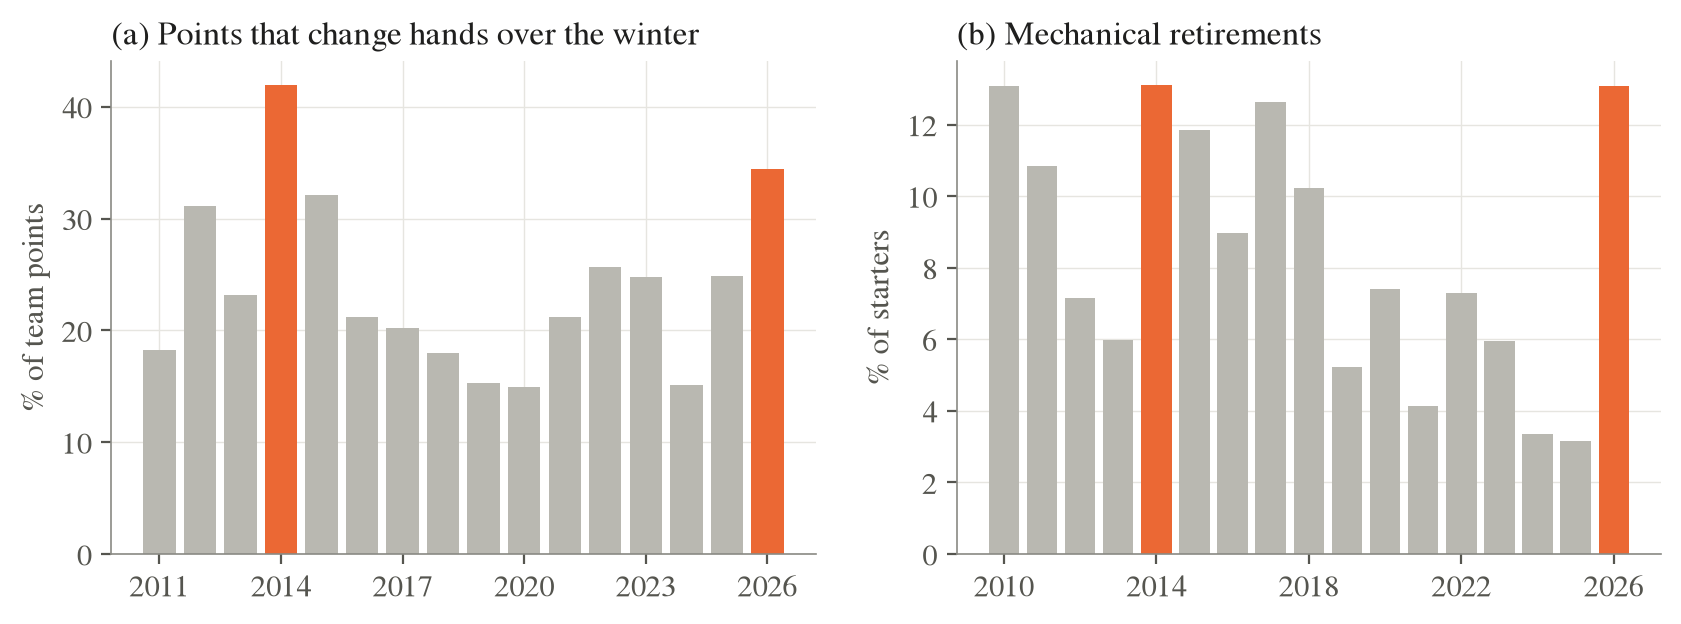

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from f1duel.data import build, TEAM_STATS
from f1duel.plots import style, title, save, BLUE, ORANGE, AQUA, GREY, INK, INK2, MUTED, TIER_COLORS
style(); pd.set_option('display.width', 140); pd.set_option('display.max_columns', 20)
d = build()
import json
from f1duel.reset import MODELS
R = json.load(open('../results/reset_summary.json'))
F = R['facts']
print(f"Points that changed hands over the winter: 2014 {F['points_changing_hands']['2014']:.0%}, 2026 {F['points_changing_hands']['2026']:.0%} (median of other years {np.median([v for y, v in F['points_changing_hands'].items() if y not in ('2014', '2026')]):.0%})")
print(f"Mechanical retirements: 2025 {F['mechanical_dnf_rate']['2025']:.0%} -> 2026 {F['mechanical_dnf_rate']['2026']:.0%}; 2013 {F['mechanical_dnf_rate']['2013']:.0%} -> 2014 {F['mechanical_dnf_rate']['2014']:.0%}")
from IPython.display import Image; display(Image('../figures/07_reset_facts.png', width=800))

In [2]:
rows = []
for test in ['Reset 2026', 'Reset 2014', 'Normal seasons 2020-2025']:
    for n, v in R[test]['models'].items():
        rows.append({'Test': test, 'Model': n, 'Cross-entropy rounds 1-5': v['logloss_early'], 'Cross-entropy rounds 6+': v['logloss_late'],
                     'Cross-entropy all': v['logloss'], 'AUC': v['auc'], 'Precision = recall (of 10)': v['named'] / 10, 'Gain vs grid': v['gain_vs_grid'][0]})
T = pd.DataFrame(rows).set_index(['Test', 'Model']).round(4); T

Cross-entropy rounds 1-5  Cross-entropy rounds 6+  Cross-entropy all     AUC  \
Test                     Model                                                                                                      
Reset 2026               Past results only                             0.5559                   0.4906             0.5089  0.8283   
                         Past results + power unit                     0.5633                   0.4912             0.5114  0.8263   
                         Grid position only                            0.5080                   0.5034             0.5047  0.8294   
                         Weekend pace only                             0.5269                   0.4709             0.4866  0.8470   
                         Full model (no power unit)                    0.5102                   0.4629             0.4762  0.8518   
                         Full model                                    0.5135                   0.4617             0.4762  0.8509   
Reset 2014               Past results only                             0.5045                   0.4510             0.4655  0.8523   
                         Past results + power unit                     0.4897                   0.4573             0.4660  0.8507   
                         Grid position only                            0.4713                   0.4955             0.4889  0.8436   
                         Weekend pace only                             0.4590                   0.4763             0.4716  0.8572   
                         Full model (no power unit)                    0.4430                   0.4274             0.4316  0.8764   
                         Full model                                    0.4374                   0.4333             0.4344  0.8730   
Normal seasons 2020-2025 Past results only                             0.5258                   0.5292             0.5284  0.8168   
                         Past results + power unit                     0.5280                   0.5282             0.5282  0.8169   
                         Grid position only                            0.5028                   0.5095             0.5080  0.8297   
                         Weekend pace only                             0.5048                   0.5080             0.5072  0.8374   
                         Full model (no power unit)                    0.4809                   0.4790             0.4795  0.8551   
                         Full model                                    0.4821                   0.4785             0.4793  0.8551   

                                                     Precision = recall (of 10)  Gain vs grid  
Test                     Model                                                                 
Reset 2026               Past results only                               0.7647        0.1176  
                         Past results + power unit                       0.7529        0.0000  
                         Grid position only                              0.7529        0.0000  
                         Weekend pace only                               0.7647        0.1176  
                         Full model (no power unit)                      0.7647        0.1176  
                         Full model                                      0.7647        0.1176  
Reset 2014               Past results only                               0.7737        0.1579  
                         Past results + power unit                       0.7632        0.0526  
                         Grid position only                              0.7579        0.0000  
                         Weekend pace only                               0.7526       -0.0526  
                         Full model (no power unit)                      0.7684        0.1053  
                         Full model                                      0.7579        0.0000  
Normal seasons 2020-2025 Past results only      

Reset 2026: H1 weekend beats past early by +0.0290 cross-entropy; H2 gap later +0.0197 (positive = weekend better); power unit changes the full model by +0.0000
Reset 2014: H1 weekend beats past early by +0.0456 cross-entropy; H2 gap later -0.0253 (positive = weekend better); power unit changes the full model by +0.0028


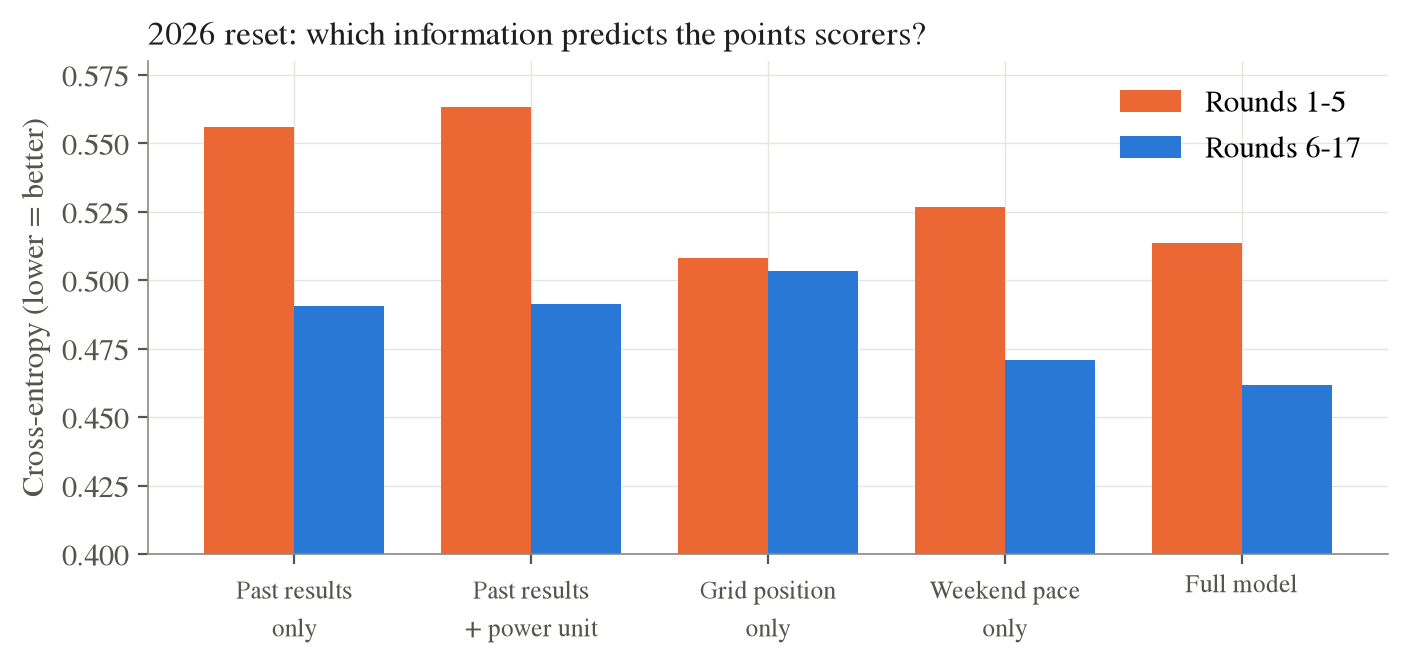

In [3]:
for test in ['Reset 2026', 'Reset 2014']:
    m = R[test]['models']
    e = m['Past results only']['logloss_early'] - m['Weekend pace only']['logloss_early']
    l = m['Past results only']['logloss_late'] - m['Weekend pace only']['logloss_late']
    pu = m['Full model']['logloss'] - m['Full model (no power unit)']['logloss']
    print(f"{test}: H1 weekend beats past early by {e:+.4f} cross-entropy; H2 gap later {l:+.4f} (positive = weekend better); power unit changes the full model by {pu:+.4f}")
from IPython.display import Image; display(Image('../figures/07_reset_2026.png', width=700))

**Reading.** H1 holds in both resets: in the first five races, the weekend's pace predicts the points scorers better than past results. H2 holds too: the gap shrinks as the season goes on (in 2014, past results even become the better source after round 5). The full model, which combines both, is best overall. The power-unit variables do **not** improve the full model: the engine's past results are themselves "past results", which a reset makes stale; what matters is visible on Saturday.